## EDA - vroeggeboorte per provincie, 2015–2024
**Younes Et-Talby · Thema 2: Vroeggeboorte**

Deze verkennende data-analyse onderzoekt de structuur, verdelingen en datakwaliteit van de synthetische Perined-dataset voor 2015–2024. De bevindingen onderbouwen de keuzes voor de ETL-pijplijn. Mijn deelvraag gaat over de aanvullende voorspellende waarde van CBS-SES-WOA voor provinciale vroeggeboortepercentages.

De gegevens bevatten fictieve geboorteregistraties. De verdieping richt zich op zwangerschapsduur, SES, demografische kenmerken en stedelijkheid. De resultaten beschrijven de simulatie en zijn geen gemeten Nederlandse zorgcijfers.

## 1. Data inlezen en structuur

De synthetische dataset bevat 100.000 fictieve geboorteregistraties en 46 kolommen. De Perined-metadata wordt gebruikt om de benodigde kolommen en geselecteerde waarden te controleren. Ook worden bijvoorbeeld de gemiddelde leeftijd en het aantal ontbrekende waarden vergeleken met de cijfers uit de metadata.

Alle velden worden eerst als tekst ingelezen, zodat postcodes en categoriewaarden behouden blijven. Daarna worden meetwaarden, zoals leeftijd en geboortegewicht, omgezet naar getallen. Waarden die niet kunnen worden omgezet, worden apart geteld. De oorspronkelijke gegevens blijven ongewijzigd, de analyse wordt uitgevoerd op een kopie van de dataset.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_rows', 60)

raw = pd.read_csv('Perined_synthetische_2015_2024.csv',
                  dtype='string', keep_default_na=False, na_values=[''])
print('Aantal registraties:', len(raw))
print('Aantal kolommen:', raw.shape[1])

Aantal registraties: 100000
Aantal kolommen: 46


## 2. Structuur en datakwaliteit

De gegevens worden in een werkkopie gecontroleerd. Spaties aan het begin en einde van waarden worden verwijderd. Omdat alle kolommen eerst als tekst zijn ingelezen, worden meetwaarden zoals leeftijd en geboortegewicht daarna omgezet naar getallen. Waarden waarbij dit niet lukt, worden apart geteld. Het overzicht toont per kolom het datatype, het percentage ontbrekende waarden en het aantal verschillende ingevulde waarden.

In [2]:
numeriek = ['jaar', 'lft', 'ses_percentiel', 'par', 'grav', 'amddd',
            'amww', 'geboortegew', 'apgar5', 'hoftiezer', 'amddd1ond']
nodig = numeriek + ['provincie', 'pc4', 'stedelijkheid']
ontbreekt = [kolom for kolom in nodig if kolom not in raw.columns]
if ontbreekt:
    raise ValueError('Benodigde kolommen ontbreken: ' + ', '.join(ontbreekt))

df = raw.copy()
randspaties = 0
for kolom in raw.columns:
    schoon = raw[kolom].str.strip()
    randspaties += int((raw[kolom].notna() & raw[kolom].ne(schoon)).sum())
    df[kolom] = schoon.replace('', pd.NA)

omzettingsfouten = {}
for kolom in numeriek:
    getallen = pd.to_numeric(df[kolom], errors='coerce')
    omzettingsfouten[kolom] = int((df[kolom].notna() & getallen.isna()).sum())
    df[kolom] = getallen

print('Waarden met randspaties:', randspaties)
display(pd.Series(omzettingsfouten, name='Niet als getal leesbaar').to_frame())
structuur = pd.DataFrame({
    'Datatype': df.dtypes.astype(str),
    'Leeg (%)': df.isna().mean() * 100,
    'Unieke ingevulde waarden': df.nunique()
})
display(structuur.round(3))

Waarden met randspaties: 0


,Niet als getal leesbaar
jaar,0
lft,0
ses_percentiel,0
par,0
grav,0
amddd,0
amww,0
geboortegew,0
apgar5,0
hoftiezer,0


,Datatype,Leeg (%),Unieke ingevulde waarden
ovdr12,string,0.000,5
verantw_zw,string,0.000,3
verantw_bb,string,0.000,3
verantw_eb,string,0.000,3
jaar,Int64,0.000,10
pc4,string,0.239,2877
provincie,string,0.000,13
gebplaats,string,0.312,6
type_partus,string,3.134,5
beginbaring_detail,string,2.624,6


**Bevinding.** De dataset bevat 100.000 registraties en 46 kolommen. Alle ingevulde waarden in de onderzochte meetkolommen konden worden omgezet naar getallen. Er zijn geen spaties aan het begin of einde van waarden gevonden. Zeven kolommen zijn volledig leeg, waaronder rookgedrag, etnic en sectio_ia.

**Betekenis voor de ETL.** Meetwaarden krijgen een numeriek datatype, postcodes en categorieaanduidingen blijven tekst. Lege waarden worden niet automatisch ingevuld met nul of ‘nee’. Per bewerking wordt bepaald welke velden nodig zijn. Een registratie wordt daardoor niet verwijderd vanwege een leeg veld dat voor die bewerking niet wordt gebruikt.

In [3]:
print('Volledig lege kolommen:', df.columns[df.isna().all()].tolist())
print('Kolommen met één unieke ingevulde waarde:', df.columns[df.nunique() == 1].tolist())
print('Volledig identieke rijen:', raw.duplicated().sum())

# Deze ingevulde waarden betekenen volgens de metadata 'onbekend'.
onbekendwaarden = {
    'provincie': '99',
    'beginbaring_basis': '9',
    'gesl': 'UNK',
    'ligging': 'UNK',
    'rookgedrag': 'UNK'
}

onbekend = []

for kolom, waarde in onbekendwaarden.items():
    onbekend.append({
        'Kolom': kolom,
        'Onbekendwaarde': waarde,
        'Aantal onbekend': df[kolom].eq(waarde).sum(),
        'Aantal leeg': df[kolom].isna().sum()
    })

display(pd.DataFrame(onbekend))

Volledig lege kolommen: ['congenafw1', 'congenafw6', 'congenafw7', 'congenafw8', 'etnic', 'rookgedrag', 'sectio_ia']
Kolommen met één unieke ingevulde waarde: ['whodef', 'congenafw5', 'vrouwniveau']
Volledig identieke rijen: 0


,Kolom,Onbekendwaarde,Aantal onbekend,Aantal leeg
0,provincie,99,37613,0
1,beginbaring_basis,9,483,2624
2,gesl,UNK,0,57
3,ligging,UNK,0,2742
4,rookgedrag,UNK,0,100000


**Bevinding.** Er zijn geen volledig identieke rijen gevonden. Bij 37.613 registraties is de provincie onbekend, aangegeven met 99. Bij het begin van de baring betekent 9 ook onbekend, dit komt 483 keer voor.

**Betekenis voor de ETL.** Onbekende waarden worden per kolom gecontroleerd. Registraties zonder bekende provincie worden apart geteld en niet meegenomen in provinciale berekeningen. Gelijke kenmerken zijn geen reden om automatisch rijen te verwijderen, omdat ze bij verschillende geboorten kunnen horen. De kolom whodef bevat overal dezelfde waarde en biedt daardoor geen onderscheid als voorspeller.

In [4]:
jaren = list(range(2015, 2025))
toegestane_provincies = [str(n) for n in range(1, 13)] + ['99']

# Controle van de verwachte waarden in de synthetische dataset.
controles = pd.Series({
    'Jaar buiten 2015–2024':
        (~df['jaar'].dropna().isin(jaren)).sum(),
    'Niet-toegestane provincie':
        (~df['provincie'].dropna().isin(toegestane_provincies)).sum(),
    'SES buiten 1–100':
        (~df['ses_percentiel'].dropna().between(1, 100)).sum(),
    'Leeftijd buiten verwacht bereik (15–49)':
        (~df['lft'].dropna().between(15, 49)).sum(),
    'Zwangerschapsduur buiten verwacht bereik (168–300 dagen)':
        (~df['amddd'].dropna().between(168, 300)).sum(),
    'Negatieve pariteit':
        (df['par'].dropna() < 0).sum(),
    'Graviditeit kleiner dan 1':
        (df['grav'].dropna() < 1).sum(),
    'Geboortegewicht buiten verwacht bereik (350–6500 gram)':
        (~df['geboortegew'].dropna().between(350, 6500)).sum()
}, name='Aantal afwijkingen')

display(controles.to_frame())

# Alleen registraties met beide ingevulde velden worden vergeleken.
duur_paar = df[['amddd', 'amww']].dropna()
zwangerschappen = df[['grav', 'par']].dropna()

logische_controles = pd.DataFrame({
    'Controle': [
        'Dagen passen niet bij hele weken',
        'Graviditeit niet groter dan pariteit'
    ],
    'Beoordeelbare registraties': [
        len(duur_paar),
        len(zwangerschappen)
    ],
    'Aantal afwijkingen': [
        (duur_paar['amddd'] // 7 != duur_paar['amww']).sum(),
        (zwangerschappen['grav'] <= zwangerschappen['par']).sum()
    ]
})

display(logische_controles)

# Een ingevulde PC4 moet uit vier cijfers bestaan en niet met nul beginnen.
pc4 = df['pc4'].dropna()
print('Afwijkend PC4-formaat:',
      (~pc4.str.fullmatch(r'[1-9][0-9]{3}')).sum())

,Aantal afwijkingen
Jaar buiten 2015–2024,0
Niet-toegestane provincie,0
SES buiten 1–100,0
Leeftijd buiten verwacht bereik (15–49),0
Zwangerschapsduur buiten verwacht bereik (168–300 dagen),0
Negatieve pariteit,0
Graviditeit kleiner dan 1,0
Geboortegewicht buiten verwacht bereik (350–6500 gram),0


,Controle,Beoordeelbare registraties,Aantal afwijkingen
0,Dagen passen niet bij hele weken,100000,0
1,Graviditeit niet groter dan pariteit,99198,0


Afwijkend PC4-formaat: 0


**Bevinding.** De uitgevoerde controles laten geen afwijkingen zien. Leeftijd, zwangerschapsduur en geboortegewicht vallen binnen de gekozen grenzen van de synthetische dataset. De ingevulde postcodes hebben het juiste PC4-formaat. Dit toont nog niet aan dat ze bij de juiste provincie horen.

**Betekenis voor de ETL.** Afwijkingen worden eerst onderzocht voordat waarden worden aangepast of verwijderd. Bij echte Perined-data worden de grenzen opnieuw beoordeeld. Deze controles geven geen volledige beoordeling van de medische juistheid van alle gegevens.

In [5]:
kernvelden = ['ses_percentiel', 'lft', 'par', 'stedelijkheid']

# Ontbrekende waarden per kernveld.
ontbrekend = df[kernvelden].isna().sum().to_frame('Aantal ontbrekend')
ontbrekend['Ontbrekend (%)'] = 100 * ontbrekend['Aantal ontbrekend'] / len(df)
display(ontbrekend.round(3))

# Hoeveel kernvelden ontbreken bij dezelfde registratie?
ontbrekend_per_rij = df[kernvelden].isna().sum(axis=1)

overzicht = (
    ontbrekend_per_rij.value_counts()
    .sort_index()
    .to_frame('Aantal registraties')
)
overzicht.index.name = 'Aantal ontbrekende kernvelden'

display(overzicht)

,Aantal ontbrekend,Ontbrekend (%)
ses_percentiel,794,0.794
lft,295,0.295
par,431,0.431
stedelijkheid,1684,1.684


,Aantal registraties
Aantal ontbrekende kernvelden,
0,96824
1,3148
2,28


**Bevinding.** SES ontbreekt bij 794 registraties, leeftijd bij 295, pariteit bij 431 en stedelijkheid bij 1.684. Bij 96.824 registraties zijn alle vier de kernvelden ingevuld. Bij 3.148 registraties ontbreekt een kernveld en bij 28 ontbreken er twee.

**Betekenis voor de ETL.** Een registratie kan meerdere lege velden hebben. Daarom wordt per selectie berekend hoeveel registraties overblijven. Ontbrekende waarden worden niet automatisch met nul ingevuld. De meeste ontbrekende waarden zijn in deze synthetische dataset willekeurig geplaatst. Bij echte gegevens moet opnieuw worden onderzocht waar en waarom waarden ontbreken.

## 3. Vergelijking met de Perined-metadata

De tabel vergelijkt leeftijd, SES-percentiel, zwangerschapsduur en geboortegewicht met de cijfers uit de Perined-metadata. Deze beschrijft 1.853.378 registraties uit 2010-2020. De gemiddelden en medianen worden naast elkaar gezet. Ontbrekende waarden worden als percentages vergeleken, omdat de datasets niet even groot zijn.

**Keuzes bij het maken van de synthetische dataset**

De gemiddelden, medianen en aantallen ontbrekende waarden uit de Perined-metadata zijn gebruikt als uitgangspunt. De aantallen ontbrekende waarden zijn omgerekend naar 100.000 registraties. Het historische profiel uit 2010–2020 is toegepast op 2015–2024, dit is een aanname. Ook de verbanden tussen SES, leeftijd, pariteit, zwangerschapsduur en geboortegewicht zijn gesimuleerd. Extreme bronwaarden, zoals onwaarschijnlijk hoge geboortegewichten, zijn niet als realistische grenzen overgenomen. De EDA controleert hoe deze keuzes terugkomen in de verdelingen, ontbrekende waarden en verbanden.

In [6]:
aantal_metadata = 1_853_378

referentie = pd.DataFrame({
    'Gemiddelde metadata': {
        'lft': 31,
        'ses_percentiel': 51,
        'amddd': 276,
        'geboortegew': 3406
    },
    'Mediaan metadata': {
        'lft': 31,
        'ses_percentiel': 51,
        'amddd': 278,
        'geboortegew': 3440
    },
    'Aantal leeg metadata': {
        'lft': 5463,
        'ses_percentiel': 14715,
        'amddd': 0,
        'geboortegew': 2167
    }
})

kolommen = referentie.index

referentie['Gemiddelde synthetisch'] = df[kolommen].mean()
referentie['Mediaan synthetisch'] = df[kolommen].median()
referentie['Leeg metadata (%)'] = (
    100 * referentie['Aantal leeg metadata'] / aantal_metadata
)
referentie['Leeg synthetisch (%)'] = (
    100 * df[kolommen].isna().mean()
)

volgorde = [
    'Gemiddelde metadata', 'Gemiddelde synthetisch',
    'Mediaan metadata', 'Mediaan synthetisch',
    'Leeg metadata (%)', 'Leeg synthetisch (%)'
]

display(referentie[volgorde].round(3))

,Gemiddelde metadata,Gemiddelde synthetisch,Mediaan metadata,Mediaan synthetisch,Leeg metadata (%),Leeg synthetisch (%)
lft,31,31.524,31,32.0,0.295,0.295
ses_percentiel,51,50.994,51,51.0,0.794,0.794
amddd,276,275.488,278,278.0,0.000,0.000
geboortegew,3406,3412.692,3440,3438.0,0.117,0.117


**Bevinding.** De gemiddelde leeftijd is 31,52 jaar, tegenover 31 jaar in de metadata. De gemiddelde zwangerschapsduur is 275,49 dagen, tegenover 276 dagen. De percentages ontbrekende waarden komen na afronding overeen.

**Betekenis voor de ETL.** De cijfers uit de metadata zijn gebruikt bij het maken van de synthetische dataset. De overeenkomst is daardoor deels vooraf bepaald. De metadata dient als vergelijkingspunt, verschillen worden niet automatisch gecorrigeerd. Overeenkomstige gemiddelden bewijzen niet dat alle gesimuleerde verbanden realistisch zijn. Bij de echte dataset worden de controles opnieuw uitgevoerd.

## 4. Verdelingen en verbanden

De kolommen (lft), (par) en (grav) bevatten de leeftijd van de moeder, het aantal eerdere bevallingen en het aantal zwangerschappen. De zwangerschapsduur staat in dagen (amddd) en hele weken (amww). Het geboortegewicht (geboortegew) is uitgedrukt in gram.

De tabel toont onder andere het gemiddelde, de mediaan, de spreiding en de laagste en hoogste waarde. De histogrammen laten zien welke waarden vaak of weinig voorkomen.

,lft,ses_percentiel,par,grav,amddd,amww,geboortegew
count,99705.0,99206.0,99569.0,99628.0,100000.0,100000.0,99883.0
mean,31.52,50.99,0.84,2.1,275.49,38.93,3412.69
std,5.12,28.49,0.98,1.11,13.54,1.91,553.1
min,15.0,1.0,0.0,1.0,168.0,24.0,468.0
25%,28.0,26.0,0.0,1.0,270.0,38.0,3094.0
50%,32.0,51.0,1.0,2.0,278.0,39.0,3438.0
75%,35.0,76.0,1.0,3.0,284.0,40.0,3776.0
max,49.0,100.0,7.0,10.0,300.0,42.0,5657.0


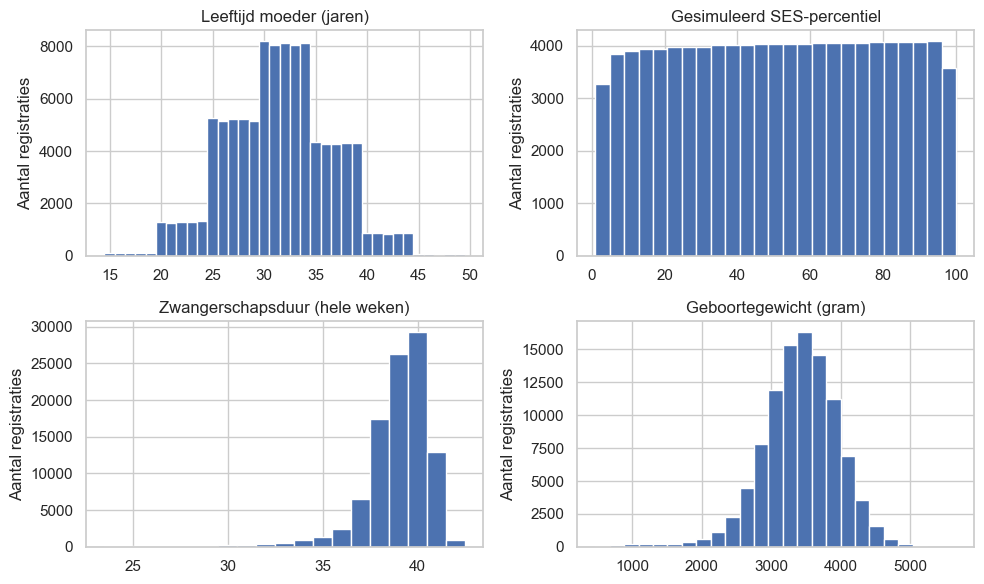

In [7]:
meetvelden = [
    'lft', 'ses_percentiel', 'par', 'grav',
    'amddd', 'amww', 'geboortegew'
]

display(df[meetvelden].describe().round(2))

grafiekdata = df[
    ['lft', 'ses_percentiel', 'amww', 'geboortegew']
].astype(float)

grafiekdata = grafiekdata.rename(columns={
    'lft': 'Leeftijd moeder (jaren)',
    'ses_percentiel': 'Gesimuleerd SES-percentiel',
    'amww': 'Zwangerschapsduur (hele weken)',
    'geboortegew': 'Geboortegewicht (gram)'
})

# Eén vak per leeftijdsjaar en per hele zwangerschapsweek.
vakken = {
    'Leeftijd moeder (jaren)': [n - 0.5 for n in range(15, 51)],
    'Gesimuleerd SES-percentiel': 25,
    'Zwangerschapsduur (hele weken)': [n - 0.5 for n in range(24, 44)],
    'Geboortegewicht (gram)': 25
}

fig, assen = plt.subplots(2, 2, figsize=(10, 6))

for ax, kolom in zip(assen.flat, grafiekdata.columns):
    waarden = grafiekdata[kolom].dropna()
    ax.hist(waarden, bins=vakken[kolom])
    ax.set_title(kolom)
    ax.set_ylabel('Aantal registraties')

plt.tight_layout()
plt.show()
plt.close()

De meeste geboorten liggen in deze synthetische dataset rond 39-40 hele weken. De SES-percentielen lopen van 1 tot 100. Deze waarden zijn gesimuleerd en verschillen in betekenis en schaal van de CBS-SES-WOA-scores.

De IQR is de afstand tussen het 25e en 75e percentiel. Waarden die meer dan 1,5 keer de IQR onder het 25e of boven het 75e percentiel liggen, worden gemarkeerd als mogelijke uitschieters. Zo’n waarde hoeft geen fout te zijn. De spreidingsgrafiek toont maximaal 5.000 punten om leesbaar te blijven. De tabellen gebruiken alle beschikbare registraties.

,Kolom,Ondergrens,Bovengrens,Aantal mogelijke uitschieters
0,lft,17.5,45.5,503
1,par,-1.5,2.5,6415
2,amddd,249.0,305.0,3721
3,geboortegew,2071.0,4799.0,2022


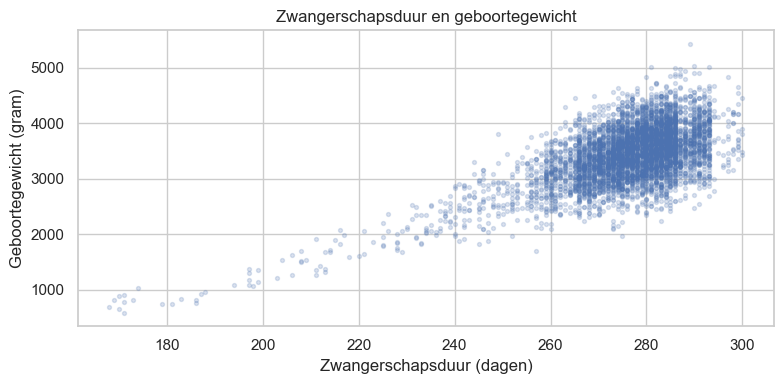

In [8]:
uitschieters = []

for kolom in ['lft', 'par', 'amddd', 'geboortegew']:
    waarden = df[kolom].dropna()

    q1 = waarden.quantile(0.25)
    q3 = waarden.quantile(0.75)
    iqr = q3 - q1

    ondergrens = q1 - 1.5 * iqr
    bovengrens = q3 + 1.5 * iqr

    aantal = ((waarden < ondergrens) | (waarden > bovengrens)).sum()

    uitschieters.append({
        'Kolom': kolom,
        'Ondergrens': ondergrens,
        'Bovengrens': bovengrens,
        'Aantal mogelijke uitschieters': aantal
    })

display(pd.DataFrame(uitschieters).round(2))

# Alleen voor de grafiek worden maximaal 5.000 registraties gebruikt.
punten = df[['amddd', 'geboortegew']].dropna()
punten = punten.sample(n=min(5000, len(punten)), random_state=42)

plt.figure(figsize=(8, 4))
plt.scatter(punten['amddd'], punten['geboortegew'], s=8, alpha=0.2)
plt.xlabel('Zwangerschapsduur (dagen)')
plt.ylabel('Geboortegewicht (gram)')
plt.title('Zwangerschapsduur en geboortegewicht')
plt.tight_layout()
plt.show()
plt.close()

**Bevinding.** De IQR-regel markeert 3.721 zwangerschapsduren en 2.022 geboortegewichten als mogelijke uitschieters. De grafiek laat zien dat een kortere zwangerschapsduur in deze synthetische dataset vaak samengaat met een lager geboortegewicht.

Bij pariteit markeert de IQR-regel 6.415 registraties met drie of meer eerdere bevallingen als mogelijke uitschieters. Deze waarden zijn niet automatisch onjuist. De grens is statistisch bepaald en houdt geen rekening met de inhoudelijke betekenis van pariteit.

**Betekenis voor de ETL.** Een mogelijke uitschieter is niet automatisch een fout. Vroeggeboorten zijn juist belangrijk voor het onderzoek. Deze registraties worden daarom behouden, tenzij verdere controle aanleiding geeft om ze aan te passen of uit te sluiten.

Voor de volgende analyses geldt een zwangerschapsduur korter dan 259 dagen als vroeggeboorte. Dit komt overeen met een geboorte voor 37 voltooide weken. Binnen deze synthetische dataset worden alleen gehele waarden van 168 tot en met 300 dagen gebruikt. Bij een ontbrekende of afwijkende waarde blijft de uitkomst onbekend.

Het vroeggeboortepercentage wordt berekend door het aantal vroeggeboorten te delen door het aantal registraties met een geldige zwangerschapsduur en dit te vermenigvuldigen met 100.

In [9]:
# Alleen gehele zwangerschapsduren van 168 tot en met 300 dagen zijn geldig.
duur = df['amddd']
duur_geldig = (
    duur.between(168, 300) & (duur % 1 == 0)
).fillna(False)

# True = vroeggeboorte, False = geen vroeggeboorte, NA = onbekend.
df['vroeggeboorte'] = (duur < 259).astype('boolean')
df.loc[~duur_geldig, 'vroeggeboorte'] = pd.NA

print('Aantal vroeggeboorten:', df['vroeggeboorte'].sum())
print('Registraties met geldige duur:', df['vroeggeboorte'].count())
print('Vroeggeboorte (%):', round(100 * df['vroeggeboorte'].mean(), 3))

# SES verdelen in vier groepen.
df['ses_groep'] = pd.cut(
    df['ses_percentiel'],
    bins=[0, 25, 50, 75, 100],
    labels=['1–25', '>25–50', '>50–75', '>75–100']
)

# Aantallen en vroeggeboortepercentage per SES-groep.
ses_tabel = df.groupby('ses_groep', observed=False).agg(
    registraties=('jaar', 'size'),
    geldige_duur=('vroeggeboorte', 'count'),
    vroeggeboorten=('vroeggeboorte', 'sum')
)

ses_tabel['vroeggeboorte_pct'] = (
    100 * ses_tabel['vroeggeboorten'] / ses_tabel['geldige_duur']
)

display(ses_tabel.round(3))

Aantal vroeggeboorten: 6707
Registraties met geldige duur: 100000
Vroeggeboorte (%): 6.707


,registraties,geldige_duur,vroeggeboorten,vroeggeboorte_pct
ses_groep,,,,
1–25,23870,23870,1800,7.541
>25–50,25051,25051,1751,6.99
>50–75,25298,25298,1550,6.127
>75–100,24987,24987,1561,6.247


**Bevinding.** Er zijn 6.707 vroeggeboorten bij 100.000 registraties met een geldige zwangerschapsduur 6,707%. Van de laagste naar de hoogste SES-groep zijn de percentages 7,54%, 6,99%, 6,13% en 6,25%. Het percentage daalt dus niet bij elke volgende groep. Deze verschillen zijn deels ingebouwd bij het maken van de synthetische dataset. Ze bewijzen geen oorzakelijk verband en laten nog niet zien of SES de voorspelling verbetert.

leeftijdsgroep


,geldige_duur,vroeggeboorten,vroeggeboorte_pct
leeftijdsgroep,,,
15–19,510,39,7.647
20–24,6439,448,6.958
25–29,26040,1778,6.828
30–34,40579,2573,6.341
35–39,21523,1503,6.983
40–49,4614,343,7.434


pariteitsgroep


,geldige_duur,vroeggeboorten,vroeggeboorte_pct
pariteitsgroep,,,
0,44157,3113,7.05
1,35628,2256,6.332
2 of meer,19784,1303,6.586


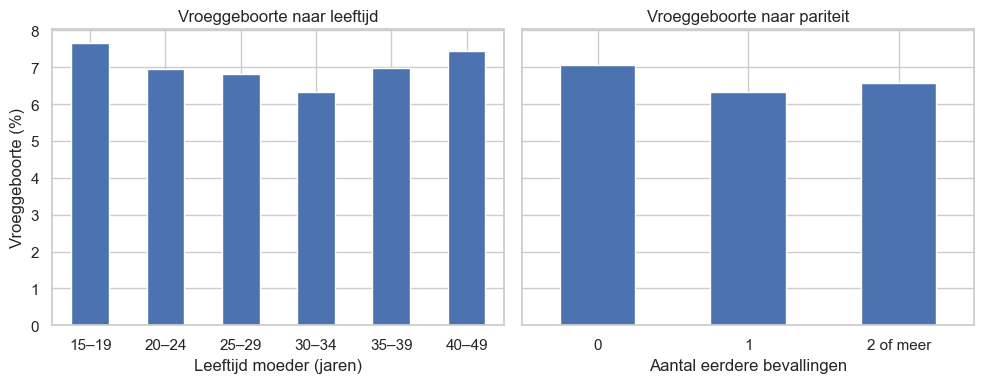

In [10]:
# Leeftijd en pariteit verdelen in groepen.
df['leeftijdsgroep'] = pd.cut(
    df['lft'],
    bins=[14, 19, 24, 29, 34, 39, 49],
    labels=['15–19', '20–24', '25–29', '30–34', '35–39', '40–49']
)

df['pariteitsgroep'] = pd.cut(
    df['par'],
    bins=[-1, 0, 1, float('inf')],
    labels=['0', '1', '2 of meer']
)

fig, assen = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

for ax, kolom in zip(assen, ['leeftijdsgroep', 'pariteitsgroep']):
    tabel = df.groupby(kolom, observed=False).agg(
        geldige_duur=('vroeggeboorte', 'count'),
        vroeggeboorten=('vroeggeboorte', 'sum')
    )

    tabel['vroeggeboorte_pct'] = (
        100 * tabel['vroeggeboorten'] / tabel['geldige_duur']
    )

    print(kolom)
    display(tabel.round(3))

    tabel['vroeggeboorte_pct'].plot.bar(ax=ax, rot=0)

    if kolom == 'leeftijdsgroep':
        ax.set_title('Vroeggeboorte naar leeftijd')
        ax.set_xlabel('Leeftijd moeder (jaren)')
    else:
        ax.set_title('Vroeggeboorte naar pariteit')
        ax.set_xlabel('Aantal eerdere bevallingen')

    ax.set_ylabel('Vroeggeboorte (%)')

plt.tight_layout()
plt.show()
plt.close()

**Bevinding.** In de synthetische dataset hebben de leeftijdsgroepen 15-19 en 40-49 jaar een hoger vroeggeboortepercentage dan de groep 30-34 jaar. Bij nul eerdere bevallingen ligt het percentage hoger dan bij een eerdere bevalling. Bij deze vergelijkingen is geen rekening gehouden met andere kenmerken, zoals SES.

**Betekenis voor de ETL.** De oorspronkelijke getalswaarden van leeftijd en pariteit blijven behouden. De groepen worden alleen gebruikt om de resultaten overzichtelijk te beschrijven.

In [11]:
# Lange omschrijvingen vervangen door korte groepsnamen.
stedelijke_labels = {
    'zeer sterk stedelijk >=2500 adressen per km2': 'Zeer sterk',
    'sterk stedelijk 1500-2500 adressen per km2': 'Sterk',
    'matig stedelijk 1000 - 1500 adressen per km2': 'Matig',
    'weinig stedelijk 500-1000 adressen per km2': 'Weinig',
    'niet stedelijk < 500 adressen per km2': 'Niet stedelijk'
}

df['stedelijkheid_groep'] = df['stedelijkheid'].map(stedelijke_labels)

# Controleren of alle ingevulde omschrijvingen worden herkend.
niet_herkend = (
    df['stedelijkheid'].notna()
    & df['stedelijkheid_groep'].isna()
)
print('Niet-herkende ingevulde waarden:', niet_herkend.sum())

# Zeer sterk en sterk stedelijk samenvoegen in een indicator.
df['sterk_stedelijk'] = (
    df['stedelijkheid_groep']
    .isin(['Zeer sterk', 'Sterk'])
    .astype('boolean')
)

# Een onbekende groep blijft onbekend.
df.loc[df['stedelijkheid_groep'].isna(), 'sterk_stedelijk'] = pd.NA

# Vroeggeboortepercentage per stedelijkheidsgroep.
stedelijk_tabel = df.groupby('stedelijkheid_groep').agg(
    geldige_duur=('vroeggeboorte', 'count'),
    vroeggeboorten=('vroeggeboorte', 'sum')
)

stedelijk_tabel['vroeggeboorte_pct'] = (
    100 * stedelijk_tabel['vroeggeboorten']
    / stedelijk_tabel['geldige_duur']
)

volgorde = list(stedelijke_labels.values())
display(stedelijk_tabel.reindex(volgorde).round(3))

Niet-herkende ingevulde waarden: 0


,geldige_duur,vroeggeboorten,vroeggeboorte_pct
stedelijkheid_groep,,,
Zeer sterk,24759,1766,7.133
Sterk,25067,1697,6.77
Matig,19230,1242,6.459
Weinig,17423,1159,6.652
Niet stedelijk,11837,719,6.074


**Bevinding.** Alle vijf stedelijkheidsgroepen worden herkend. Het vroeggeboortepercentage is 7,13% bij zeer sterk stedelijke registraties en 6,07% bij niet-stedelijke registraties.

**Betekenis voor de ETL.** Ontbrekende stedelijkheid blijft onbekend en wordt niet ingedeeld als (niet stedelijk). Vergelijkingen tussen de groepen gebruiken alleen registraties met bekende stedelijkheid en een geldige zwangerschapsduur. Luchtkwaliteit kan met deze CSV niet worden onderzocht, omdat deze gegevens ontbreken.

## 5. Vroeggeboorte per provincie en jaar

De provincie-indeling volgt de Perined-metadata. Registraties uit 2015–2024 met een bekende provincie worden per provincie en jaar samengevoegd. De tabel toont het aantal vroeggeboorten, het aantal registraties met een geldige zwangerschapsduur en de gemiddelde kenmerken. Ook wordt bijgehouden hoeveel ingevulde waarden voor deze gemiddelden beschikbaar zijn.

In [12]:
# Provincienamen volgens de Perined-metadata.
provincies = {
    '1': 'Friesland',
    '2': 'Drenthe',
    '3': 'Overijssel',
    '4': 'Gelderland',
    '5': 'Limburg',
    '6': 'Noord-Brabant',
    '7': 'Zeeland',
    '8': 'Zuid-Holland',
    '9': 'Noord-Holland',
    '10': 'Utrecht',
    '11': 'Flevoland',
    '12': 'Groningen'
}

# Registraties selecteren binnen de periode met een bekende provincie.
in_periode = df['jaar'].isin(jaren)
provincie_bekend = df['provincie'].isin(provincies)

regionaal = df.loc[in_periode & provincie_bekend].copy()

# Aantallen en gemiddelden per provincie en jaar berekenen.
provincie_jaar = regionaal.groupby(['jaar', 'provincie']).agg(
    n_registraties=('jaar', 'size'),
    n_duur_bekend=('vroeggeboorte', 'count'),
    n_vroeg=('vroeggeboorte', 'sum'),
    n_ses_bekend=('ses_percentiel', 'count'),
    gem_ses_percentiel=('ses_percentiel', 'mean'),
    n_leeftijd_bekend=('lft', 'count'),
    gem_leeftijd=('lft', 'mean'),
    n_pariteit_bekend=('par', 'count'),
    gem_pariteit=('par', 'mean'),
    n_stedelijkheid_bekend=('sterk_stedelijk', 'count'),
    aandeel_sterk_stedelijk=('sterk_stedelijk', 'mean')
).reset_index()

provincie_jaar['provincienaam'] = (
    provincie_jaar['provincie'].map(provincies)
)

provincie_jaar['vroeggeboorte_pct'] = (
    100 * provincie_jaar['n_vroeg']
    / provincie_jaar['n_duur_bekend']
)

# Percentage registraties waarvoor SES bekend is.
provincie_jaar['ses_dekking_pct'] = (
    100 * provincie_jaar['n_ses_bekend']
    / provincie_jaar['n_registraties']
)

print('Aantal geselecteerde registraties:', len(regionaal))
print('Aantal combinaties van provincie en jaar:', len(provincie_jaar))
print('Kleinste aantal registraties met geldige duur:',
      provincie_jaar['n_duur_bekend'].min())

toon_kolommen = [
    'jaar',
    'provincienaam',
    'n_duur_bekend',
    'n_vroeg',
    'vroeggeboorte_pct',
    'gem_ses_percentiel',
    'ses_dekking_pct'
]

display(provincie_jaar[toon_kolommen].round(3).head(12))

Aantal geselecteerde registraties: 62387
Aantal combinaties van provincie en jaar: 120
Kleinste aantal registraties met geldige duur: 88


,jaar,provincienaam,n_duur_bekend,n_vroeg,vroeggeboorte_pct,gem_ses_percentiel,ses_dekking_pct
0,2015,Friesland,213,15,7.042,40.133,99.061
1,2015,Utrecht,551,30,5.445,55.057,99.093
2,2015,Flevoland,177,11,6.215,51.113,100.0
3,2015,Groningen,179,9,5.028,35.916,99.441
4,2015,Drenthe,163,4,2.454,43.317,98.773
5,2015,Overijssel,402,30,7.463,46.895,99.751
6,2015,Gelderland,754,54,7.162,47.129,99.072
7,2015,Limburg,330,32,9.697,37.44,97.879
8,2015,Noord-Brabant,885,64,7.232,49.379,98.983
9,2015,Zeeland,122,7,5.738,42.95,99.18


**Bevinding.** Er zijn 62.387 registraties met een bekende provincie. Deze zijn samengevoegd tot 120 combinaties: twaalf provincies over tien jaar. De overige 37.613 registraties hebben een onbekende provincie. Het kleinste aantal registraties met een geldige zwangerschapsduur binnen een provincie en jaar is 88.

**Betekenis voor de ETL.** Registraties zonder bekende provincie worden apart geteld en niet meegenomen in provinciale berekeningen. Naast de percentages blijven de aantallen behouden. Bij kleinere aantallen kan een extra vroeggeboorte het percentage sterker veranderen. Daarom worden provinciale percentages altijd samen met de bijbehorende aantallen beoordeeld.

,geldige_duur,vroeggeboorten,provincie_onbekend_pct,vroeggeboorte_pct
jaar,,,,
2015,10046,704,37.418,7.008
2016,10164,689,38.282,6.779
2017,10006,709,38.527,7.086
2018,9929,641,36.257,6.456
2019,9997,684,37.371,6.842
2020,9938,668,37.613,6.722
2021,10572,682,37.609,6.451
2022,9869,656,37.714,6.647
2023,9691,652,37.437,6.728


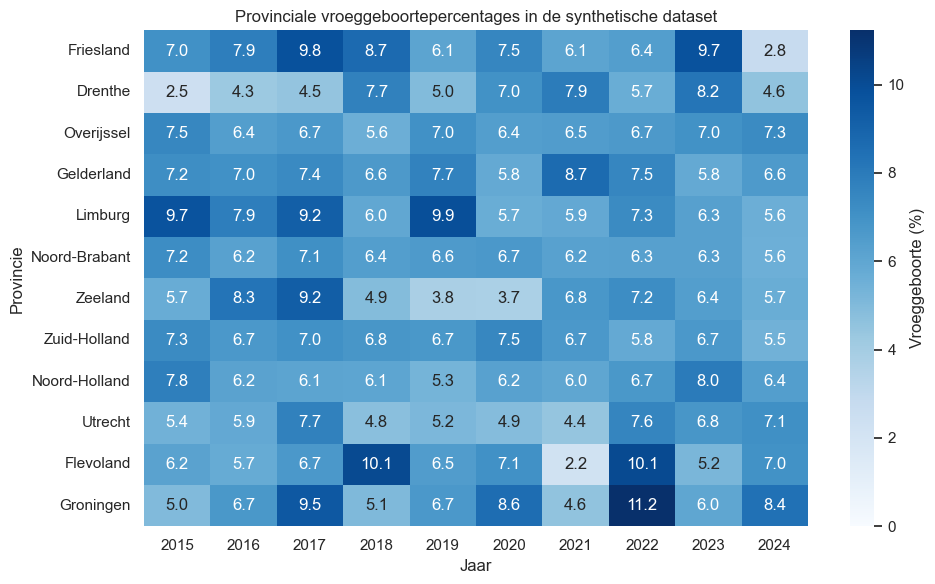

In [13]:
# Jaaroverzicht, inclusief registraties met een onbekende provincie.
jaar_data = df.loc[in_periode].copy()
jaar_data['provincie_onbekend'] = (
    ~jaar_data['provincie'].isin(provincies)
)

jaaroverzicht = jaar_data.groupby('jaar').agg(
    geldige_duur=('vroeggeboorte', 'count'),
    vroeggeboorten=('vroeggeboorte', 'sum'),
    provincie_onbekend_pct=('provincie_onbekend', 'mean')
)

jaaroverzicht['vroeggeboorte_pct'] = (
    100 * jaaroverzicht['vroeggeboorten']
    / jaaroverzicht['geldige_duur']
)

jaaroverzicht['provincie_onbekend_pct'] = (
    100 * jaaroverzicht['provincie_onbekend_pct']
)

display(jaaroverzicht.round(3))

# Provincies als rijen en jaren als kolommen.
trends = provincie_jaar.pivot(
    index='provincie',
    columns='jaar',
    values='vroeggeboorte_pct'
)

trends = trends.reindex(
    index=list(provincies),
    columns=jaren
).astype(float)

trends.index = trends.index.map(provincies)

# Percentages weergeven in een heatmap.
plt.figure(figsize=(10, 6))
sns.heatmap(
    trends,
    annot=True,
    fmt='.1f',
    cmap='Blues',
    vmin=0,
    cbar_kws={'label': 'Vroeggeboorte (%)'}
)

plt.xlabel('Jaar')
plt.ylabel('Provincie')
plt.title('Provinciale vroeggeboortepercentages in de synthetische dataset')
plt.tight_layout()
plt.show()
plt.close()

**Bevinding.** De 62.387 registraties met een bekende provincie leveren alle 120 combinaties van provincie en jaar op. De kleinste groep bevat 88 registraties. Het totale vroeggeboortepercentage daalt van 7,01% in 2015 naar 6,36% in 2024, met tussentijdse schommelingen. De provincies laten verschillende ontwikkelingen zien.

**Betekenis voor de ETL.** Bij kleine groepen kunnen enkele extra vroeggeboorten het percentage sterk veranderen. Daarom blijven de aantallen naast de percentages beschikbaar. Per jaar is bij ongeveer 36-39% van de registraties de provincie onbekend. Dit beperkt de dekking van de provinciale analyse.

In de volgende grafiek en correlaties telt elke combinatie van provincie en jaar even zwaar, ongeacht het aantal registraties. Dezelfde provincie komt meerdere jaren terug, de uitkomsten binnen een provincie kunnen met elkaar samenhangen. Deze analyses beschrijven verbanden. Of kenmerken de voorspelling verbeteren, moet later met modeltoetsing worden onderzocht.

,vroeggeboorte_pct
gem_ses_percentiel,-0.144
gem_leeftijd,-0.086
gem_pariteit,-0.066
aandeel_sterk_stedelijk,0.101


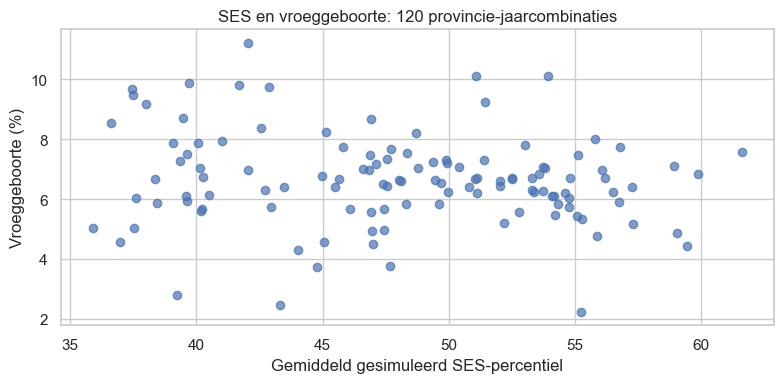

In [14]:
kenmerken = [
    'gem_ses_percentiel',
    'gem_leeftijd',
    'gem_pariteit',
    'aandeel_sterk_stedelijk'
]

# Lineaire samenhang tussen de kenmerken en het vroeggeboortepercentage
correlaties = (
    provincie_jaar[kenmerken + ['vroeggeboorte_pct']]
    .astype(float)
    .corr(method='pearson')
)

display(
    correlaties.loc[kenmerken, ['vroeggeboorte_pct']].round(3)
)

# Alleen combinaties met een bekend SES-gemiddelde en percentage tonen
grafiekdata = provincie_jaar[
    ['gem_ses_percentiel', 'vroeggeboorte_pct']
].dropna()

plt.figure(figsize=(8, 4))
plt.scatter(
    grafiekdata['gem_ses_percentiel'],
    grafiekdata['vroeggeboorte_pct'],
    alpha=0.7
)

plt.xlabel('Gemiddeld gesimuleerd SES-percentiel')
plt.ylabel('Vroeggeboorte (%)')
plt.title(f'SES en vroeggeboorte: {len(grafiekdata)} provincie-jaarcombinaties')
plt.tight_layout()
plt.show()
plt.close()

**Bevinding.** In de synthetische dataset is de Pearson-correlatie tussen het gemiddelde SES-percentiel en het vroeggeboortepercentage ongeveer −0,14. Dit wijst op een zwakke negatieve lineaire samenhang. Deze berekening gaat over combinaties van provincie en jaar, het verband kan anders zijn bij individuele registraties. Of SES de voorspelling verbetert, wordt later onderzocht door modellen met en zonder SES op dezelfde apart gehouden testjaren te vergelijken.

In [15]:
# Alleen registraties met bekende SES, leeftijd en pariteit.
compleet = regionaal.dropna(
    subset=['ses_percentiel', 'lft', 'par']
)

selecties = [
    ('Alle registraties binnen de periode', df.loc[in_periode]),
    ('Provincie bekend', regionaal),
    ('Provincie onbekend of leeg',
     df.loc[in_periode & ~provincie_bekend]),
    ('Provincie, SES, leeftijd en pariteit bekend', compleet)
]

selectieoverzicht = []

for naam, selectie in selecties:
    selectieoverzicht.append({
        'Selectie': naam,
        'Registraties': len(selectie),
        'Geldige duur': int(selectie['vroeggeboorte'].count()),
        'Vroeggeboorten': int(selectie['vroeggeboorte'].sum()),
        'Vroeggeboorte (%)': (
            100 * selectie['vroeggeboorte'].mean()
        ),
        'SES ontbreekt (%)': (
            100 * selectie['ses_percentiel'].isna().mean()
        )
    })

display(pd.DataFrame(selectieoverzicht).round(3))

,Selectie,Registraties,Geldige duur,Vroeggeboorten,Vroeggeboorte (%),SES ontbreekt (%)
0,Alle registraties binnen de periode,100000,100000,6707,6.707,0.794
1,Provincie bekend,62387,62387,4135,6.628,0.825
2,Provincie onbekend of leeg,37613,37613,2572,6.838,0.742
3,"Provincie, SES, leeftijd en pariteit bekend",61435,61435,4075,6.633,0.000


**Bevinding.** Bij registraties met een bekende provincie is het vroeggeboortepercentage 6,628%, tegenover 6,707% in de volledige dataset. Als daarnaast SES, leeftijd en pariteit ingevuld moeten zijn, vallen nog 952 registraties buiten de selectie. Het percentage wordt dan 6,633%.

**Betekenis voor de ETL.** De selectie met drie ingevulde kenmerken wordt alleen gebruikt om te controleren hoe het uitsluiten van ontbrekende waarden het percentage verandert. Dit wordt geen standaardstap in de verwerking. Het kleine verschil in deze synthetische dataset bewijst niet dat dezelfde selectie bij echte gegevens geen vertekening veroorzaakt.

In [16]:
print(
    'Dubbele combinaties van provincie en jaar:',
    provincie_jaar.duplicated(['jaar', 'provincie']).sum()
)

print(
    'Totaal aantal registraties klopt:',
    provincie_jaar['n_registraties'].sum() == len(regionaal)
)

print(
    'Aantal registraties met geldige duur klopt:',
    provincie_jaar['n_duur_bekend'].sum()
    == regionaal['vroeggeboorte'].count()
)

print(
    'Totaal aantal vroeggeboorten klopt:',
    provincie_jaar['n_vroeg'].sum()
    == regionaal['vroeggeboorte'].sum()
)

print(
    'Percentages buiten 0–100:',
    (~provincie_jaar['vroeggeboorte_pct']
     .dropna().between(0, 100)).sum()
)

print(
    'PC4 aanwezig in provinciale tabel:',
    'pc4' in provincie_jaar.columns
)

Dubbele combinaties van provincie en jaar: 0
Totaal aantal registraties klopt: True
Aantal registraties met geldige duur klopt: True
Totaal aantal vroeggeboorten klopt: True
Percentages buiten 0–100: 0
PC4 aanwezig in provinciale tabel: False


## 6. Conclusie en ETL-keuzes

De synthetische dataset is bruikbaar om de gegevensverwerking voor te bereiden. De controles op waardebereiken en logische combinaties laten geen afwijkingen zien binnen de gekozen grenzen. Belangrijke aandachtspunten zijn ontbrekende en onbekende waarden, mogelijke uitschieters en verschillen in groepsgrootte.

| Bevinding | Keuze voor de ETL | Controle |
| --- | --- | --- |
| Lege en expliciet onbekende waarden | Per kolom verwerken, niet automatisch met nul invullen of onvolledige rijen verwijderen | Ontbrekende en onbekende waarden apart tellen |
| 37.613 registraties met onbekende provincie | Buiten provinciale berekeningen houden en apart verantwoorden | Selecties met bekende en onbekende provincie vergelijken |
| Geldige zwangerschapsduur nodig voor de uitkomst | Bij ontbrekende of ongeldige duur de uitkomst onbekend laten | Aantal geldige registraties naast vroeggeboorten bewaren |
| Mogelijke uitschieters | Eerst beoordelen, vroeggeboorten niet automatisch verwijderen | Waardebereiken en verbanden controleren |
| Samenvatten per provincie en jaar | Aantallen, gemiddelden en dekking behouden | Unieke combinaties en aansluiting van tellingen controleren |
| PC4 niet nodig in provinciale uitvoer | Alleen benodigde gegevens doorgeven | Controleren dat PC4 ontbreekt in de samenvatting |

De analysetabel bevat 120 combinaties van provincie en jaar. De 100.000 bronregistraties vormen daardoor geen 100.000 afzonderlijke modelvoorbeelden. De aanvullende voorspellende waarde van CBS-SES-WOA moet later met echte gegevens worden onderzocht.

Bij de echte dataset moeten de onderzochte populatie, de berekening van het percentage, de omgang met meerlingen en doodgeboorten en de betekenis van de provincie worden bevestigd. Ook moet duidelijk zijn welke kenmerken op het voorspelmoment beschikbaar zijn.

De synthetische dataset bevat geen moeder of zwangerschaps-ID. De gesimuleerde locatiegegevens gebruiken een referentie uit 2024 en geven geen volledige historische werkelijkheid weer. Provinciale verbanden mogen niet rechtstreeks worden vertaald naar persoonlijke risico’s. Bij echte gegevens blijven toegangsbeheer en controle van de uitvoer nodig, een samenvatting per provincie garandeert op zichzelf geen anonimiteit.

## Bronnen

Centraal Bureau voor de Statistiek. *[Hoe interpreteer je de SES-WOA-scores en hoe zijn deze bepaald?](https://www.cbs.nl/nl-nl/faq/infoservice/hoe-interpreteer-je-de-ses-woa-scores-en-hoe-zijn-deze-bepaald-)*

Perined. *Meta Data Perinatale Zorg - voorbeeld*